# 292. Keeping nanopore reads by translated reduced-alphabet k-mers: tarantula venom gland, Conotoxin family

**Question.** A nanopore sequencer can eject a read part-way through and load another one
(adaptive sampling). readfish, the usual tool, decides from the first chunk of signal by
mapping it to a DNA reference with minimap2 (https://pypi.org/project/readfish/). The
rule tested here works on protein instead: translate the first few hundred bases in six
frames, encode them in a reduced amino-acid alphabet, and count k-mers shared with a set of
reference proteins. For a read from an animal with no genome, can this rule decide "this
read is from protein family X" when DNA mapping to the nearest relatives cannot?

**Decision rule, written before any result (from the experiment brief,
[`292_data/experiment_brief.md`](292_data/experiment_brief.md), Olga's task description
for this notebook).** The sample's
genus is held out of the reference. Continue the idea if the best k-mer setting keeps at
least half of the family reads while keeping 5% or fewer of the other reads, and the DNA
rule keeps under 10% of the family reads. If the DNA rule keeps as many family reads
as the k-mer rule, the cross-species claim is dead.

**What the reader decides from this notebook.** Whether a translated k-mer filter is
worth building into an adaptive-sampling client for non-model animals, and how far from
the reference proteins it still works.

**Data.**
- Reads: SRA run SRR32537183, venom gland of the Philippine tarantula *Selenobrachys
  ustromsupasius* (isolate RR2-11), cDNA by ONT kit SQK-PCS111 on a MinION with an R9
  flow cell, released 2025-11-15. 200_000 reads sampled from the 8_425_614 in the run
  (seed 20261014). The basecaller and its version are not stated in the SRA record.
- Proteins: Swiss-Prot release 2026_03.
- Target family: Pfam PF02950 (Conotoxin), chosen in section 2.
- N is the chunk: the first N bases of a read, which is all the rule sees.
- The alphabets come from kmerseek, this project's protein search tool: "protein" keeps the
  20 amino acids; "dayhoff" groups them into 6 classes by chemistry; "hp" keeps 2 classes,
  hydrophobic and polar (section 4 lists the residues in each class).
- k is the k-mer length in residues; m is the minimum number of the chunk's k-mers that
  must also be in the reference for the read to be kept.
- A setting is one combination of alphabet, k and m.
- "Genus held out" and "tarantulas held out" name two reference sets (section 2); "family
  read" always means a read from the protein family PF02950.

The computation is in [`scripts/adaptive/`](../scripts/adaptive/); this notebook reads
its tables and draws the figures. The decision itself is
[`scripts/adaptive/decide.py`](../scripts/adaptive/decide.py): a translator, a set of
k-mers and a rule, in standard-library Python.

In [1]:
import os
import sys

import numpy as np
import polars as pl

sys.path.insert(0, os.path.abspath("."))
import adaptive_sampling_utils as u
import pubfig as pf

pf.use_style()
pl.Config.set_tbl_rows(100)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(80)
FIG = "../figures/292"
os.makedirs(FIG, exist_ok=True)
DATA_292 = "292_data"
print("data folder:", u.DATA)

data folder: /Users/olga/data/adaptive_sampling


## 1. Reads

The SRA was searched for Oxford Nanopore transcriptome runs released from 2021 on, from a
venom gland or a tunicate (exact queries in
[`292_data/sra_queries.txt`](292_data/sra_queries.txt)). A venomous marine animal was
preferred. The marine venomous animals found are cnidarians sequenced as the whole animal
or as eggs (the sea anemone *Exaiptasia diaphana*, SRR32136522, 2_157_359 reads, direct
RNA; the corals *Pocillopora damicornis* and *Platygyra daedalea*; *Nematostella
vectensis* eggs), not venom glands. A whole cnidarian dilutes its toxins among all other
transcripts, so a venom-gland run was picked instead. The largest runs in the list are
honeybee whole bodies and larvae, and the king cobra run is pooled organs. Of the runs whose
sample record says "venom gland", SRR32537183
has the most reads (8_425_614). Its kit, SQK-PCS111 (2021), is newer than the
SQK-DCS109 kit of the only other venom-gland run of similar size, SRR33222190 (the
tarantula *Pterinochilus murinus*, 3_867_987 reads). Both runs used R9 flow cells. R10
flow cells, which have a lower error rate, were not found.

Every download is listed in the table below. The SRA file came from NCBI's AWS mirror,
because ENA served the FASTQ at 160 kB/s.

In [2]:
runs = pl.concat(
    [
        pl.read_csv(
            f"{DATA_292}/sra_runinfo_query1_venom_or_tunicate.csv",
            infer_schema_length=0,
        ),
        pl.read_csv(
            f"{DATA_292}/sra_runinfo_query2_venomous_taxa.csv", infer_schema_length=0
        ),
    ]
).unique("Run")
print(f"{runs.height} distinct runs from the two SRA queries")
print(
    runs.with_columns(pl.col("spots").cast(pl.Int64))
    .sort("spots", descending=True)
    .select(
        "Run",
        "ReleaseDate",
        "ScientificName",
        "spots",
        "avgLength",
        "Model",
        "BioProject",
        "SampleName",
    )
    .head(12)
)
dl = pl.read_csv(f"{DATA_292}/downloads.tsv", separator="\t")
print(dl)

159 distinct runs from the two SRA queries
shape: (12, 8)
┌─────────────┬─────────────────────┬─────────────────────────────┬──────────┬───────────┬────────────┬──────────────┬────────────────────────────────────────────┐
│ Run         ┆ ReleaseDate         ┆ ScientificName              ┆ spots    ┆ avgLength ┆ Model      ┆ BioProject   ┆ SampleName                                 │
│ ---         ┆ ---                 ┆ ---                         ┆ ---      ┆ ---       ┆ ---        ┆ ---          ┆ ---                                        │
│ str         ┆ str                 ┆ str                         ┆ i64      ┆ str       ┆ str        ┆ str          ┆ str                                        │
╞═════════════╪═════════════════════╪═════════════════════════════╪══════════╪═══════════╪════════════╪══════════════╪════════════════════════════════════════════╡
│ SRR29180535 ┆ 2024-05-25 07:32:06 ┆ Apis cerana cerana          ┆ 48440954 ┆ 1227      ┆ PromethION ┆ PRJNA1116335 ┆ Que

shape: (2, 6)
┌───────────┬─────────┬───────────────┬─────────────┬────────────────────┬────────────────────┐
│ reads     ┆ n       ┆ median_length ┆ mean_length ┆ fraction_under_400 ┆ fraction_under_800 │
│ ---       ┆ ---     ┆ ---           ┆ ---         ┆ ---                ┆ ---                │
│ str       ┆ i64     ┆ i64           ┆ f64         ┆ f64                ┆ f64                │
╞═══════════╪═════════╪═══════════════╪═════════════╪════════════════════╪════════════════════╡
│ whole run ┆ 8425614 ┆ 726           ┆ 745.0       ┆ 0.0347             ┆ 0.852              │
│ sample    ┆ 200000  ┆ 726           ┆ 745.8       ┆ 0.0342             ┆ 0.8505             │
└───────────┴─────────┴───────────────┴─────────────┴────────────────────┴────────────────────┘


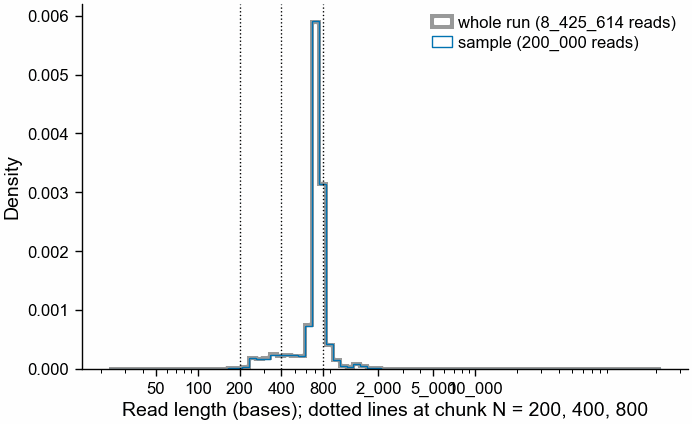

In [3]:
all_len = np.loadtxt(f"{u.DATA}/reads/SRR32537183_all_read_lengths.txt", dtype=int)
tr = u.truth()
sample_len = tr["read_length"].to_numpy()
summ = pl.DataFrame(
    {
        "reads": ["whole run", "sample"],
        "n": [len(all_len), len(sample_len)],
        "median_length": [int(np.median(all_len)), int(np.median(sample_len))],
        "mean_length": [
            round(float(all_len.mean()), 1),
            round(float(sample_len.mean()), 1),
        ],
        "fraction_under_400": [
            round(float((all_len < 400).mean()), 4),
            round(float((sample_len < 400).mean()), 4),
        ],
        "fraction_under_800": [
            round(float((all_len < 800).mean()), 4),
            round(float((sample_len < 800).mean()), 4),
        ],
    }
)
print(summ)
summ.write_csv(f"{DATA_292}/read_length_summary_SRR32537183.csv")
fig = u.fig_read_lengths(all_len, sample_len, f"{FIG}/sf1_read_lengths_SRR32537183")

**SF1.** Read lengths of the whole run (grey) and of the 200_000-read sample (blue); the
two curves should lie on top of each other. Reads shorter than the chunk N are scored on
their whole length. The share of reads shorter than 400 bases is in the table above.

## 2. Target family and held-out references

The family had to (a) be expressed in the venom gland, (b) have at least 50 Swiss-Prot
entries outside the sample's genus, and (c) be a Pfam family. The candidates are the Pfam
families of Swiss-Prot entries with the keyword "Toxin" that are the best DIAMOND hit
(section 3) of at least one read. Swiss-Prot has no entry from *Selenobrachys*, so every
entry is outside the genus. The brief says to pick the largest. Phospholipase A2
(PF00068) has the most Swiss-Prot entries (493), but only 8 of the 200_000 reads have
their best hit in it, too few to measure what share of family reads a rule keeps.
Conotoxin (PF02950) is next, with 440 entries and 21_270 reads, and it is picked. Toxin_12 has
more reads (22_510) but only 10 entries outside the tarantulas, and Toxin_20 (7_506 reads)
has none, so neither can be tested with the tarantulas held out.

Three references were built from the Swiss-Prot entries that carry PF02950: (i) all
genera, (ii) all but *Selenobrachys*, (iii) all but the taxonomic family Theraphosidae
(the tarantulas). Because Swiss-Prot has no *Selenobrachys* entry, (i) and (ii) are the
same 440 proteins, and only (ii) and (iii) are scored. Reference (ii) holds 8 tarantula
proteins from three other genera. Reference (iii) holds no spider protein at all: 431 cone
snail proteins and one sea anemone protein. Going from (ii) to (iii) therefore jumps from
"other genera of the same family" to "another phylum".

Why a tarantula toxin carries a cone snail family. Pfam's own description of PF02950 is
one line, "Conotoxins are small snail toxins that block ion channels". On the tarantula
proteins the match covers almost the whole precursor, signal peptide and propeptide
included: residues 3-74 of 79 on B1P1F1, 2-72 of 87 on B1P1F7 and 2-73 of 79 on P0DM66
(InterPro API, 2026-10-15). In B1P1F1 the signal peptide is residues 1-19 and the
propeptide 20-44 (Swiss-Prot). So membership in this family rests partly on the signal
peptide and propeptide, which section 4 shows are shared with tarantula toxins of other
families.

For the DNA rule, the coding sequence of each entry was fetched from ENA by the first EMBL
protein id in its cross-references.

shape: (14, 8)
┌─────────┬─────────────────┬─────────────────┬───────────────────────┬─────────────────┬──────────────────┬────────────────────────┬──────────────────┐
│ pfam    ┆ pfam_name       ┆ n_sprot_entries ┆ n_sprot_toxin_keyword ┆ n_outside_genus ┆ n_outside_family ┆ n_with_embl_protein_id ┆ n_reads_best_hit │
│ ---     ┆ ---             ┆ ---             ┆ ---                   ┆ ---             ┆ ---              ┆ ---                    ┆ ---              │
│ str     ┆ str             ┆ i64             ┆ i64                   ┆ i64             ┆ i64              ┆ i64                    ┆ i64              │
╞═════════╪═════════════════╪═════════════════╪═══════════════════════╪═════════════════╪══════════════════╪════════════════════════╪══════════════════╡
│ PF00068 ┆ Phospholip_A2_1 ┆ 493             ┆ 351                   ┆ 493             ┆ 493              ┆ 304                    ┆ 8                │
│ PF02950 ┆ Conotoxin       ┆ 440             ┆ 439                

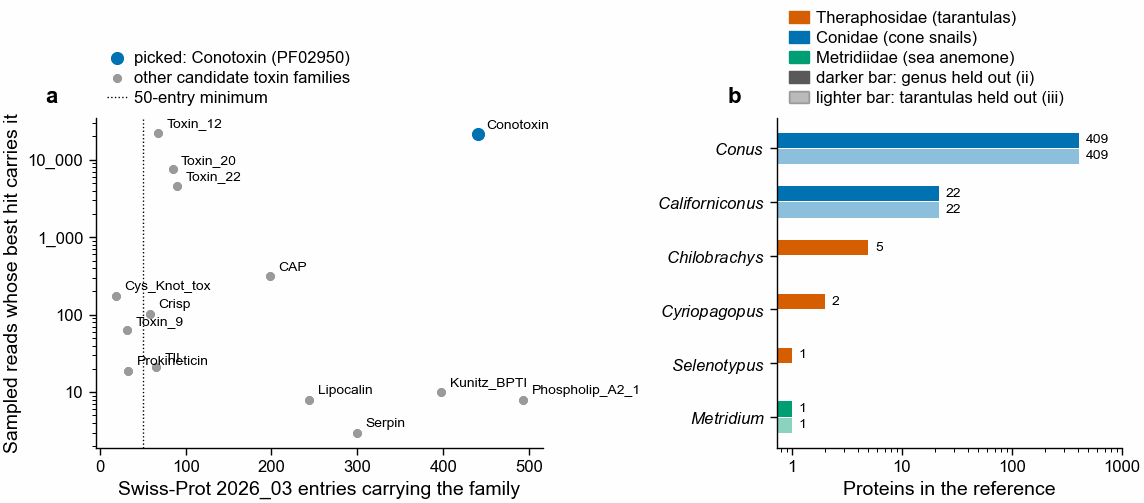

In [4]:
fam = pl.read_csv(f"{DATA_292}/toxin_family_candidates.csv")
print(fam)
refc = pl.read_csv(f"{u.DATA}/ref/{u.PFAM}/reference_counts.tsv", separator="\t")
print(refc)
refc.write_csv(f"{DATA_292}/reference_counts_{u.PFAM}_sprot_2026_03.csv")
comp = pl.read_csv(f"{DATA_292}/reference_composition_{u.PFAM}_sprot_2026_03.csv")
print(comp)
fig = u.fig_family_choice(fam, comp, f"{FIG}/fig_family_choice_sprot_2026_03")

**Family choice.** (a) Each candidate toxin family: Swiss-Prot entries (x) against sampled
reads whose best Swiss-Prot hit carries the family (y). The dotted line is the 50-entry
minimum. (b) What each held-out reference contains, by genus.

## 3. Truth per read

Every full-length read was compared with all of Swiss-Prot 2026_03 by DIAMOND blastx
(E-value 1e-5, frameshift-aware alignment, `--sensitive`, best hit by bitscore). Swiss-Prot
contains reference (i), so this is the comparison the brief asks for. A read is a family
read when its best hit carries PF02950 (the Pfam cross-reference in the Swiss-Prot entry),
a non-family read when its best hit does not, and unassigned when it has no hit.

A second truth from the species' own transcriptome was not possible. GenBank has a
transcriptome assembly of this same animal (TSA GLNU00000000, isolate RR2-11,
2_737 contigs), but it carries no protein annotations.

shape: (3, 2)
┌────────────┬─────────┐
│ label      ┆ n_reads │
│ ---        ┆ ---     │
│ str        ┆ u32     │
╞════════════╪═════════╡
│ family     ┆ 21270   │
│ non_family ┆ 161226  │
│ unassigned ┆ 17504   │
└────────────┴─────────┘
shape: (4, 4)
┌──────────┬───────────────────────────────────────────────────────────────────────────────────┬─────────┬─────────────────┐
│ best_hit ┆ best_hit_species                                                                  ┆ n_reads ┆ median_identity │
│ ---      ┆ ---                                                                               ┆ ---     ┆ ---             │
│ str      ┆ str                                                                               ┆ u32     ┆ f64             │
╞══════════╪═══════════════════════════════════════════════════════════════════════════════════╪═════════╪═════════════════╡
│ B1P1F1   ┆ Chilobrachys guangxiensis (Chinese earth tiger tarantula) (Chilobrachys jingzhao… ┆ 19772   ┆ 57.3           

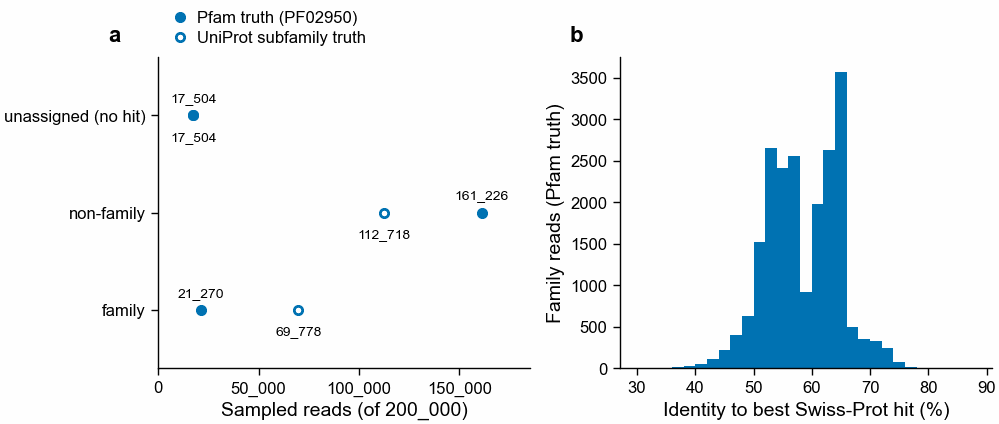

In [5]:
lab = tr.group_by("label").agg(n_reads=pl.len()).sort("label")
print(lab)
fam_reads = tr.filter(pl.col("label") == "family")
by_hit = (
    fam_reads.group_by("best_hit", "best_hit_species")
    .agg(n_reads=pl.len(), median_identity=pl.col("pident").median())
    .sort("n_reads", descending=True)
)
print(by_hit)
non = tr.filter(pl.col("label") == "non_family")
print(
    "non-family reads whose best hit has the Toxin keyword:",
    non["best_hit_is_toxin"].sum(),
    "of",
    non.height,
)
lab.write_csv(f"{DATA_292}/truth_label_counts_{u.PFAM}.csv")
by_hit.write_csv(f"{DATA_292}/truth_family_reads_by_best_hit_{u.PFAM}.csv")
tr_sub, subfams = u.subfamily_truth(tr)
print("UniProt subfamilies of the tarantula proteins in reference (ii):")
for x in subfams:
    print("  ", x)
lab_sub = tr_sub.group_by("label").agg(n_reads=pl.len()).sort("label")
print(lab_sub)
orient = (
    tr.filter(pl.col("label") != "unassigned")
    .with_columns(
        strand=pl.when(pl.col("qstart") > pl.col("qend"))
        .then(pl.lit("reverse"))
        .otherwise(pl.lit("forward")),
        aln_first_base=pl.min_horizontal("qstart", "qend"),
    )
    .group_by("label", "strand")
    .agg(
        n_reads=pl.len(),
        median_read_length=pl.col("read_length").median(),
        median_first_aligned_base=pl.col("aln_first_base").median(),
        share_alignment_overlaps_first_400=(pl.col("aln_first_base") <= 400).mean(),
        share_protein_start_in_first_400=(pl.col("qstart") <= 400).mean(),
    )
    .sort("label", "strand")
)
print(
    "Where the DIAMOND alignment of the full read sits (read bases). For reverse-strand reads the"
)
print(
    "first aligned base is the protein's C-terminal end; qstart is the protein's N-terminal end."
)
print(orient)
orient.write_csv(f"{DATA_292}/alignment_start_by_strand.csv")
moved = tr.join(
    tr_sub.select("read_id", pl.col("label").alias("label_subfamily")), on="read_id"
)
print(moved.group_by("label", "label_subfamily").len().sort("label", "label_subfamily"))
lab_sub.write_csv(f"{DATA_292}/truth_label_counts_uniprot_subfamily.csv")
fig = u.fig_truth(tr, tr_sub, f"{FIG}/fig_truth_labels_{u.PFAM}_sprot_2026_03")

**Truth labels.** (a) Reads per label, under the Pfam truth (filled) and the UniProt
subfamily truth (open). (b) Identity of each family read to its best
Swiss-Prot hit, from DIAMOND (this includes the read's sequencing errors).

The Pfam truth splits one toxin subfamily in two. B1P1F1 (U16-theraphotoxin-Cg1a), the
best hit of most family reads, carries PF02950. Its paralog B1P1F2 (U16-theraphotoxin-Cg1b)
belongs to the same UniProt subfamily ("neurotoxin 10 (Hwtx-1) family, 34 (Jztx-26)
subfamily") but has no Pfam cross-reference, so reads whose best hit is B1P1F2 count as
non-family. A second truth is therefore scored beside the brief's: a read is a family read
when its best hit belongs to a UniProt subfamily (the `CC -!- SIMILARITY` line) of one of
the tarantula proteins in reference (ii). The reference proteins and the rules do not
change; only the labels do.

Most family reads come from one transcript: their best hit is a single Swiss-Prot entry
(table above). Read counts therefore overstate how many independent genes the rule was
tested on, and the 95% intervals in later figures, which treat reads as independent, are
too narrow.

## 4. The chunk and the k-mer rule

readfish's default chunk is about 0.8 s of signal in MinKNOW 6 or later. At current
translocation speeds that is a few hundred bases, so N = 400 is the working value; N = 200
and 800 are scored too. The chunk is the first N bases of the read as sequenced, adapter
and all.

The rule: translate the chunk in six frames (standard code), encode it in one of three
alphabets that kmerseek ships (`kmerseek index --help`, kmerseek 0.3.1), and keep the read
if at least m distinct chunk k-mers are in the set of k-mers of the reference proteins.
k-mers that contain a stop codon or an untranslatable codon are skipped.

| Alphabet | Letters | Classes | k scored | sourmash default k |
|---|---|---|---|---|
| protein | 20 | one per residue | 7, 9, 10, 11 | 10 |
| dayhoff | 6 | C / AGPST / DENQ / HKR / ILMV / FWY | 10, 13, 16 | 16 |
| hp | 2 | hydrophobic AFGILMPVWY / polar NCSTDERHKQ | 20, 30, 42 | 42 |

The brief lists 20-letter k = 7, 9, 11 and says the last k of each alphabet is sourmash's
default. sourmash's default protein k is 10, not 11 (`DEFAULTS` in
`src/sourmash/command_sketch.py`), so k = 10 was added. The dayhoff and hp tables are
copied from sourmash's `encodings.rs`, which kmerseek uses for these three encodings.

Each read was scored at every setting against references (ii) and (iii). In the table,
sensitivity is family reads kept / family reads, and false keep is non-family reads kept /
non-family reads. Higher sensitivity is good; false keep should be at most 5%.

shape: (60, 8)
┌─────────┬──────────────────┬───────────────┬─────────────┬────────────┬───────────────┬────────────┬──────────────────────┐
│ holdout ┆ setting          ┆ n_family_kept ┆ sensitivity ┆ false_keep ┆ shuffled_keep ┆ enrichment ┆ pore_time_enrichment │
│ ---     ┆ ---              ┆ ---           ┆ ---         ┆ ---        ┆ ---           ┆ ---        ┆ ---                  │
│ str     ┆ str              ┆ u32           ┆ f64         ┆ f64        ┆ f64           ┆ f64        ┆ f64                  │
╞═════════╪══════════════════╪═══════════════╪═════════════╪════════════╪═══════════════╪════════════╪══════════════════════╡
│ ii      ┆ dayhoff k=10 m=1 ┆ 15673         ┆ 0.736859    ┆ 0.808207   ┆ 0.3856475     ┆ 0.933868   ┆ 0.711657             │
│ ii      ┆ dayhoff k=10 m=2 ┆ 7666          ┆ 0.360414    ┆ 0.527589   ┆ 0.1629345     ┆ 0.736952   ┆ 0.328582             │
│ ii      ┆ dayhoff k=10 m=3 ┆ 4556          ┆ 0.214198    ┆ 0.378828   ┆ 0.0673845     ┆ 0.631574   ┆ 

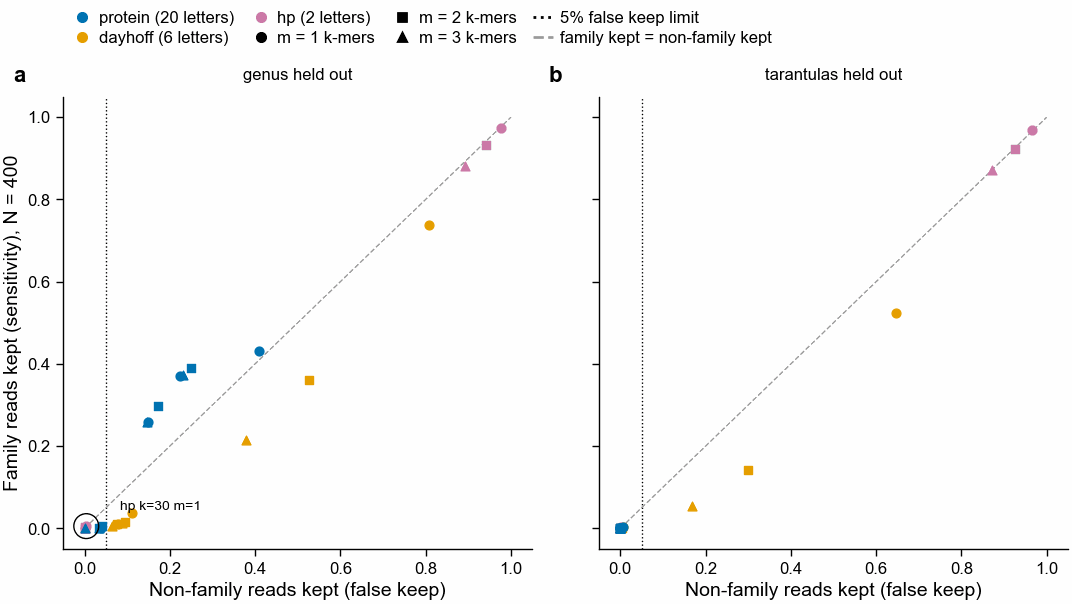

In [6]:
tab_path = f"{DATA_292}/kmer_settings_{u.PFAM}.csv"
tab = u.kmer_settings_table(tr)
tab.write_csv(tab_path)
cols = [
    "holdout",
    "setting",
    "n_family_kept",
    "sensitivity",
    "false_keep",
    "shuffled_keep",
    "enrichment",
    "pore_time_enrichment",
]
print(tab.filter(pl.col("chunk_bases_requested") == 400).select(cols))
best = u.best_setting(tab, "ii", 400)
print(
    "best setting at the genus hold-out, N = 400:",
    best.get("setting"),
    {
        k: best.get(k)
        for k in [
            "sensitivity",
            "false_keep",
            "shuffled_keep",
            "enrichment",
            "pore_time_enrichment",
        ]
    },
)
fig = u.fig_all_settings(tab, 400, best, f"{FIG}/sf2_all_kmer_settings_N400_{u.PFAM}")

**SF2.** Every k-mer setting at N = 400. Each point is one setting: x is the share of
non-family reads kept, y the share of family reads kept. Colour is the alphabet, marker
shape is m. A setting on the grey dashed diagonal keeps family and non-family reads at
the same rate, so it does not pick out the family. The circled point is the setting with the highest sensitivity at a false keep
of 5% or less with the genus held out; that is how the best setting is picked. The full
table, for N = 200, 400 and 800, is
[`292_data/kmer_settings_PF02950.csv`](292_data/kmer_settings_PF02950.csv).

Enrichment is the family share among kept reads divided by the family share among all
reads. Pore-time enrichment uses a model, not a measurement (named `pore_time_model` in the
brief): a kept read costs its full length, and an ejected read costs N bases plus 500 bases
of lost time. The 500 is the brief's number; no measurement or source stands behind it. It is the family bases sequenced per base of pore time, divided by the same
number with no ejection.

### Why the rule keeps other toxin reads

Every k-mer setting keeps a large share of non-family reads, and at the strict settings it
keeps more non-family than family reads. The table and figure below count, for protein
k = 10 (sourmash's default), each reference k-mer found in the first 400 bases of a read,
and say where it sits in the reference protein (Swiss-Prot signal peptide, propeptide, or
mature chain). A signal peptide is the 15 to 30 residues at the N-terminus that send a
protein out of the cell; it is cut off and is not part of the toxin.

shape: (12, 8)
┌────────────┬────────────────┬────────────────────┬───────────┬───────────┬─────────┬─────────────────────────┬────────────────┐
│ kmer       ┆ n_family_reads ┆ n_non_family_reads ┆ reference ┆ ref_start ┆ ref_end ┆ ref_features_overlapped ┆ ref_region     │
│ ---        ┆ ---            ┆ ---                ┆ ---       ┆ ---       ┆ ---     ┆ ---                     ┆ ---            │
│ str        ┆ i64            ┆ i64                ┆ str       ┆ i64       ┆ i64     ┆ str                     ┆ str            │
╞════════════╪════════════════╪════════════════════╪═══════════╪═══════════╪═════════╪═════════════════════════╪════════════════╡
│ IIAGLALLSV ┆ 5403           ┆ 16397              ┆ P0DM66    ┆ 6         ┆ 15      ┆ SIGNAL                  ┆ signal peptide │
│ TLAVLGVMFV ┆ 1              ┆ 6300               ┆ B1P1F3    ┆ 8         ┆ 17      ┆ SIGNAL                  ┆ signal peptide │
│ ITLAVLGVMF ┆ 0              ┆ 6038               ┆ B1P1F3    ┆ 7         

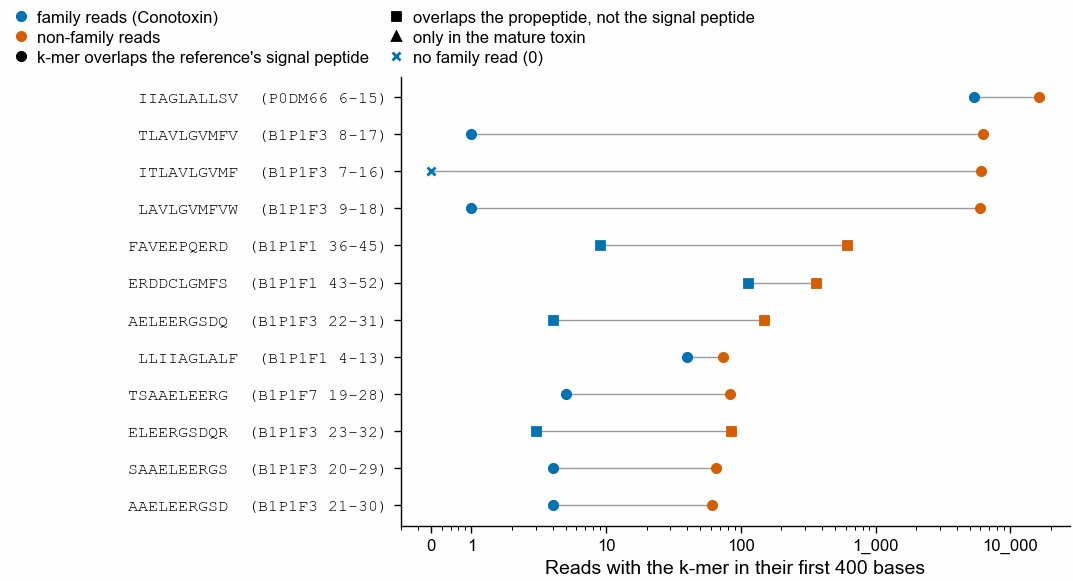

In [7]:
src = u.shared_kmer_sources(
    "ii",
    "protein",
    10,
    400,
    cache=f"{DATA_292}/shared_kmers_protein_k10_N400_genus_holdout_{u.PFAM}.csv",
)
print(src.head(12))
print(
    src.group_by("ref_region").agg(
        pl.col("n_family_reads").sum(),
        pl.col("n_non_family_reads").sum(),
        n_kmers=pl.len(),
    )
)
fig = u.fig_shared_kmers(src, f"{FIG}/fig_shared_kmers_protein_k10_N400_{u.PFAM}")

**Shared k-mers.** For the 12 reference k-mers found in the most reads (protein k = 10,
genus hold-out, N = 400), the number of family reads (blue) and non-family reads
(vermillion) whose first 400 bases contain it, in any frame. The marker shape says which part of
the precursor named on the left (residue range) the k-mer overlaps: the signal peptide, the
propeptide (and not the signal peptide), or only the mature toxin (Swiss-Prot features). The label of a
read is the brief's Pfam truth.

An example non-family read with the most common shared k-mer, compared without gaps with
the reference protein:

In [8]:
u.print_signal_peptide_example(src)

most common shared k-mer: IIAGLALLSV (5_403 family reads, 16_397 non-family reads); in P0DM66 residues 6-15, overlapping its SIGNAL
example non-family read SRR32537183.1233/1: best Swiss-Prot hit B1P1F2 (Chilobrachys guangxiensis (Chinese earth tiger tarantula) (Chilobrachys jingzhao)), Pfam none, 69.3% identity
read +1    71 TTLLLIIAGLALLSVASHALELKEQNSLKELVSAMFHMEEPLERDDCLGMFPEL*P*QRQ 130
                 | ||||||||||     | ||  |  |  |  |   || |||               
P0DM66      1 MRVLFIIAGLALLSVVCYTSEMKERSSFNEVLSEFFAADEPQERDCLGQWASCEPKNSKC 60

23 of 60 identical


## 5. Chance control

Each read was also scored as 10 copies with its bases shuffled (fixed seed), cut to the
same N. A shuffled copy keeps the read's base composition but no coding sequence, so its
keep rate is the rate at which the rule fires by chance. A setting whose real false keep is
close to its shuffled keep rate is firing at the chance rate on unrelated reads; a setting
that keeps family reads well above its shuffled rate is finding something.

shape: (60, 5)
┌─────────┬──────────────────┬────────────┬───────────────┬───────────────────────────┐
│ holdout ┆ setting          ┆ false_keep ┆ shuffled_keep ┆ sensitivity_over_shuffled │
│ ---     ┆ ---              ┆ ---        ┆ ---           ┆ ---                       │
│ str     ┆ str              ┆ f64        ┆ f64           ┆ f64                       │
╞═════════╪══════════════════╪════════════╪═══════════════╪═══════════════════════════╡
│ ii      ┆ dayhoff k=10 m=1 ┆ 0.808207   ┆ 0.3856475     ┆ 1.910707                  │
│ ii      ┆ dayhoff k=10 m=2 ┆ 0.527589   ┆ 0.1629345     ┆ 2.212016                  │
│ ii      ┆ dayhoff k=10 m=3 ┆ 0.378828   ┆ 0.0673845     ┆ 3.178749                  │
│ ii      ┆ dayhoff k=13 m=1 ┆ 0.112507   ┆ 0.005632      ┆ 6.55299                   │
│ ii      ┆ dayhoff k=13 m=2 ┆ 0.095437   ┆ 0.001328      ┆ 11.930656                 │
│ ii      ┆ dayhoff k=13 m=3 ┆ 0.087901   ┆ 0.0002875     ┆ 45.951636                 │
│ ii      ┆ dayho

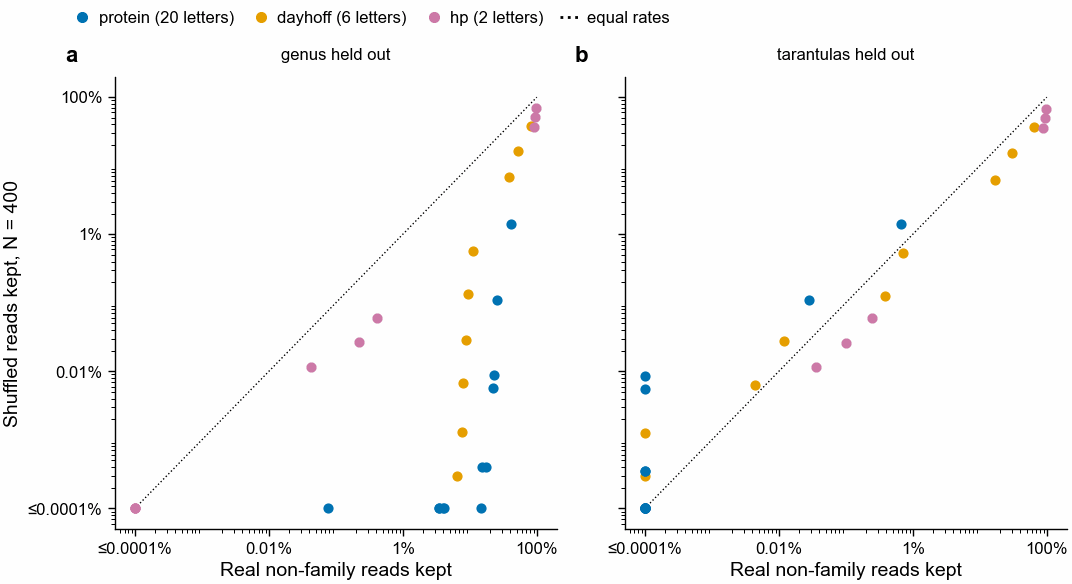

In [9]:
print(
    tab.filter(pl.col("chunk_bases_requested") == 400).select(
        "holdout",
        "setting",
        "false_keep",
        "shuffled_keep",
        (pl.col("sensitivity") / pl.col("shuffled_keep")).alias(
            "sensitivity_over_shuffled"
        ),
    )
)
fig = u.fig_shuffled(tab, 400, f"{FIG}/sf4_shuffled_vs_real_N400_{u.PFAM}")

**SF4.** For every setting at N = 400: the keep rate on real non-family reads (x) against
the keep rate on shuffled reads (y). On the dotted line the rule keeps unrelated real reads
at its chance rate. A rate of zero is drawn at the lowest tick.

## 6. Decision time

Time per decision in Python 3.13 on one core of an Apple M4 Max laptop, measured inside
`score_chunks.py` around `decide.decide()` (translation, encoding and set look-ups). The
reference k-mer set is built once, before any read, and is not timed.

shape: (10, 7)
┌──────────┬─────┬───────────┬──────────┬──────────┬────────────┬────────┐
│ alphabet ┆ k   ┆ median_ms ┆ p05_ms   ┆ p95_ms   ┆ max_ms     ┆ n      │
│ ---      ┆ --- ┆ ---       ┆ ---      ┆ ---      ┆ ---        ┆ ---    │
│ str      ┆ i32 ┆ f32       ┆ f32      ┆ f32      ┆ f32        ┆ u32    │
╞══════════╪═════╪═══════════╪══════════╪══════════╪════════════╪════════╡
│ dayhoff  ┆ 10  ┆ 0.196667  ┆ 0.178417 ┆ 0.428459 ┆ 140.920578 ┆ 200000 │
│ dayhoff  ┆ 13  ┆ 0.188916  ┆ 0.170667 ┆ 0.411584 ┆ 124.425087 ┆ 200000 │
│ dayhoff  ┆ 16  ┆ 0.182917  ┆ 0.1645   ┆ 0.397209 ┆ 151.632294 ┆ 200000 │
│ hp       ┆ 20  ┆ 0.176042  ┆ 0.156708 ┆ 0.383209 ┆ 169.98558  ┆ 200000 │
│ hp       ┆ 30  ┆ 0.160042  ┆ 0.141417 ┆ 0.347375 ┆ 136.55542  ┆ 200000 │
│ hp       ┆ 42  ┆ 0.147875  ┆ 0.130208 ┆ 0.3195   ┆ 108.519585 ┆ 200000 │
│ protein  ┆ 7   ┆ 0.207375  ┆ 0.188625 ┆ 0.457334 ┆ 148.525711 ┆ 200000 │
│ protein  ┆ 9   ┆ 0.201541  ┆ 0.183083 ┆ 0.437791 ┆ 133.927124 ┆ 200000 │
│ protein 

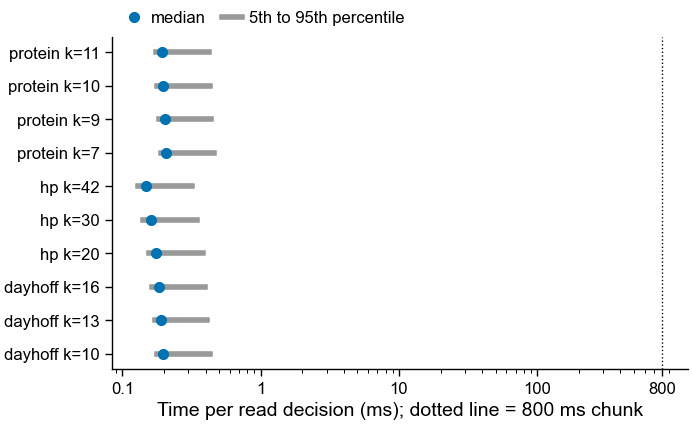

In [10]:
times = (
    u.scores()
    .filter((pl.col("copy") == 0) & (pl.col("holdout") == "ii"))
    .pipe(u.with_requested_chunk)
    .filter(pl.col("chunk_bases_requested") == 400)
    .group_by("alphabet", "k")
    .agg(
        median_ms=pl.col("decision_seconds").median() * 1000,
        p05_ms=pl.col("decision_seconds").quantile(0.05) * 1000,
        p95_ms=pl.col("decision_seconds").quantile(0.95) * 1000,
        max_ms=pl.col("decision_seconds").max() * 1000,
        n=pl.len(),
    )
    .collect()
    .sort("alphabet", "k")
)
print(times)
times.write_csv(f"{DATA_292}/decision_time_N400.csv")
fig = u.fig_decision_time(times, f"{FIG}/sf3_decision_time_N400")

**SF3.** Time per read decision at N = 400, genus hold-out: median (dot) and 5th to 95th
percentile (bar), against the 800 ms chunk (dotted line).

## 7. Comparators and the main result

On the same chunks and the same held-out references:

- **DNA rule**, as readfish does it: minimap2 2.31 `-x map-ont` of the chunk against the
  coding sequences of the reference proteins; keep when the chunk has a primary alignment.
- **DIAMOND blastx of the chunk** (the brief calls it the slow upper bound; here it does
  not separate the classes either, see F1): DIAMOND 2.2.8 blastx of the chunk alone against the reference
  proteins, E-value 1e-3, frameshift-aware (`-F 15`); keep when there is any hit. This is
  what one would do if time did not matter.

Both were also run on the shuffled copies.

In [11]:
comp_tab = u.comparator_table(tr)
comp_tab.write_csv(f"{DATA_292}/comparators_{u.PFAM}.csv")
print(
    comp_tab.select(
        "rule",
        "holdout",
        "chunk_bases_requested",
        "n_family_kept",
        "sensitivity",
        "false_keep",
        "shuffled_keep",
        "enrichment",
        "pore_time_enrichment",
    ).sort("rule", "holdout", "chunk_bases_requested")
)

shape: (12, 9)
┌─────────────────────────────┬─────────┬───────────────────────┬───────────────┬─────────────┬────────────┬───────────────┬────────────┬──────────────────────┐
│ rule                        ┆ holdout ┆ chunk_bases_requested ┆ n_family_kept ┆ sensitivity ┆ false_keep ┆ shuffled_keep ┆ enrichment ┆ pore_time_enrichment │
│ ---                         ┆ ---     ┆ ---                   ┆ ---           ┆ ---         ┆ ---        ┆ ---           ┆ ---        ┆ ---                  │
│ str                         ┆ str     ┆ i32                   ┆ u32           ┆ f64         ┆ f64        ┆ f64           ┆ f64        ┆ f64                  │
╞═════════════════════════════╪═════════╪═══════════════════════╪═══════════════╪═════════════╪════════════╪═══════════════╪════════════╪══════════════════════╡
│ DIAMOND blastx of the chunk ┆ ii      ┆ 200                   ┆ 118           ┆ 0.005548    ┆ 0.00593    ┆ 0.0001125     ┆ 0.916978   ┆ 0.004505             │
│ DIAMOND blastx of

Pfam truth (the brief's):
shape: (6, 10)
┌─────────────────────────────┬─────────────────────────────────────────────────────────────────┬─────────┬───────────────┬──────────┬─────────────┬────────────────────┬─────────────────────┬────────────┬───────────────┐
│ rule                        ┆ label                                                           ┆ holdout ┆ n_family_kept ┆ n_family ┆ sensitivity ┆ sensitivity_ci_low ┆ sensitivity_ci_high ┆ false_keep ┆ shuffled_keep │
│ ---                         ┆ ---                                                             ┆ ---     ┆ ---           ┆ ---      ┆ ---         ┆ ---                ┆ ---                 ┆ ---        ┆ ---           │
│ str                         ┆ str                                                             ┆ str     ┆ u32           ┆ i32      ┆ f64         ┆ f64                ┆ f64                 ┆ f64        ┆ f64           │
╞═════════════════════════════╪════════════════════════════════════════════

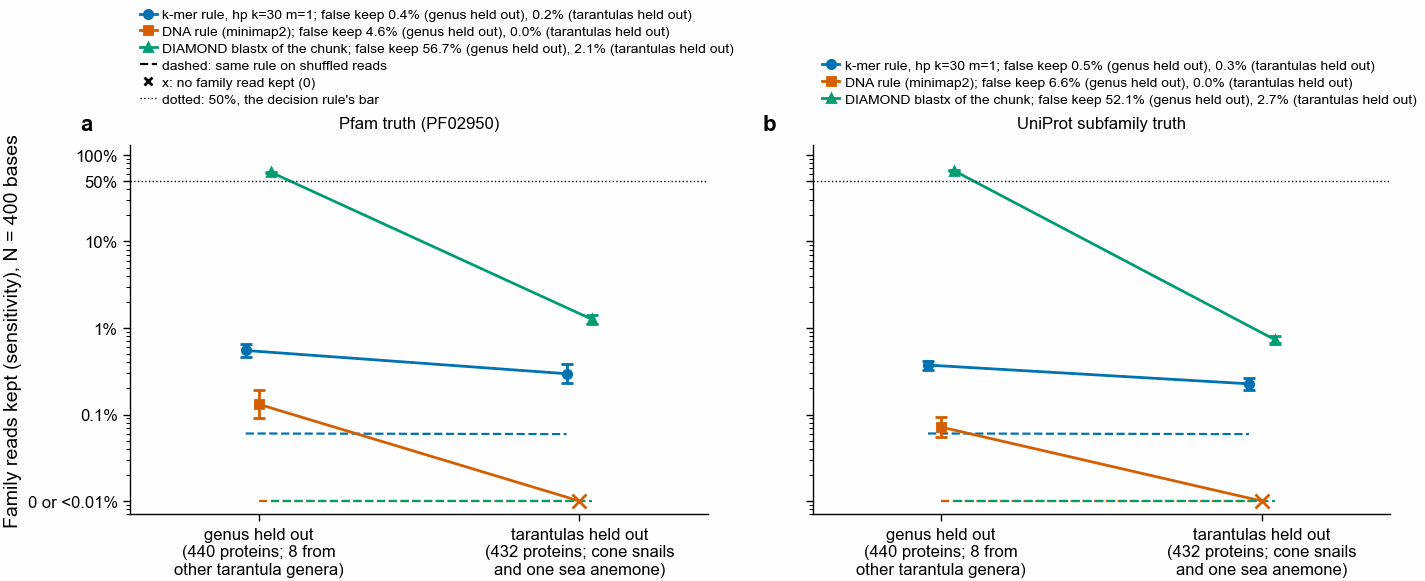

In [12]:
f1_rows, verdicts = u.main_result(tab, comp_tab, tr, n=400)
tab_sub = u.kmer_settings_table(tr_sub)
tab_sub.write_csv(f"{DATA_292}/kmer_settings_uniprot_subfamily.csv")
comp_sub = u.comparator_table(tr_sub)
comp_sub.write_csv(f"{DATA_292}/comparators_uniprot_subfamily.csv")
f1_sub, verdicts_sub = u.main_result(tab_sub, comp_sub, tr_sub, n=400)
show = [
    "rule",
    "label",
    "holdout",
    "n_family_kept",
    "n_family",
    "sensitivity",
    "sensitivity_ci_low",
    "sensitivity_ci_high",
    "false_keep",
    "shuffled_keep",
]
print("Pfam truth (the brief's):")
print(f1_rows.select(show))
print("UniProt subfamily truth:")
print(f1_sub.select(show))
f1_rows.write_csv(f"{DATA_292}/f1_sensitivity_by_holdout_N400_{u.PFAM}.csv")
f1_sub.write_csv(f"{DATA_292}/f1_sensitivity_by_holdout_N400_uniprot_subfamily.csv")
print()
for v in verdicts:
    print("Pfam truth:", v)
for v in verdicts_sub:
    print("Subfamily truth:", v)
fig = u.fig_rules_by_holdout(
    [(f1_rows, f"Pfam truth ({u.PFAM})"), (f1_sub, "UniProt subfamily truth")],
    400,
    f"{FIG}/f1_sensitivity_by_holdout_N400_{u.PFAM}",
)

**F1.** Share of family reads kept at N = 400 at each hold-out level, for the best k-mer
setting (picked at the genus hold-out by the rule in section 4 and kept fixed), the DNA rule
and DIAMOND blastx of the chunk; (a) with the brief's Pfam truth, (b) with the UniProt subfamily
truth. Bars are 95% intervals for a proportion (Wilson score interval) over reads, which
are too narrow because most family reads come from one transcript. The dashed line in each
rule's colour is that rule's keep rate on shuffled reads; the DNA rule's and DIAMOND's
dashed lines both sit at the bottom line and overlap (0 and 0.009%). The y axis is spaced by
ratio, and its bottom line holds zero and anything below 0.01%. The legend gives each rule's
share of non-family reads kept. DIAMOND on the chunk keeps family and non-family reads at
similar rates at both hold-outs (62.8% and 56.7% with the genus held out), so with these
labels no rule, fast or slow, separates the family at the read start.

The verdict sentences come from `u.verdict()`, which holds the brief's two branches. A third
branch was added after the results showed a case the brief's two do not cover. When the
k-mer rule keeps family reads at no more than twice the rate it keeps non-family reads, it
does not pick out the family. "Reaches where DNA mapping does not" would then be false,
even if its number is larger than the DNA rule's. The factor of two is a choice made here, not
taken from the brief.

## 8. Chunk length

The best k-mer setting and the DNA rule at N = 200, 400 and 800, with the genus held out.

shape: (6, 5)
┌────────────────────────────┬───────────────────────┬─────────────┬────────────┬───────────────┐
│ label                      ┆ chunk_bases_requested ┆ sensitivity ┆ false_keep ┆ shuffled_keep │
│ ---                        ┆ ---                   ┆ ---         ┆ ---        ┆ ---           │
│ str                        ┆ i32                   ┆ f64         ┆ f64        ┆ f64           │
╞════════════════════════════╪═══════════════════════╪═════════════╪════════════╪═══════════════╡
│ k-mer rule, hp k=30 m=1    ┆ 200                   ┆ 0.002398    ┆ 0.001557   ┆ 0.00022       │
│ k-mer rule, hp k=30 m=1    ┆ 400                   ┆ 0.005501    ┆ 0.004106   ┆ 0.0006035     │
│ k-mer rule, hp k=30 m=1    ┆ 800                   ┆ 0.022144    ┆ 0.015705   ┆ 0.0012305     │
│ DNA rule, minimap2 map-ont ┆ 200                   ┆ 0.0         ┆ 0.000174   ┆ 0.0           │
│ DNA rule, minimap2 map-ont ┆ 400                   ┆ 0.001316    ┆ 0.046134   ┆ 0.0           │
│ DNA 

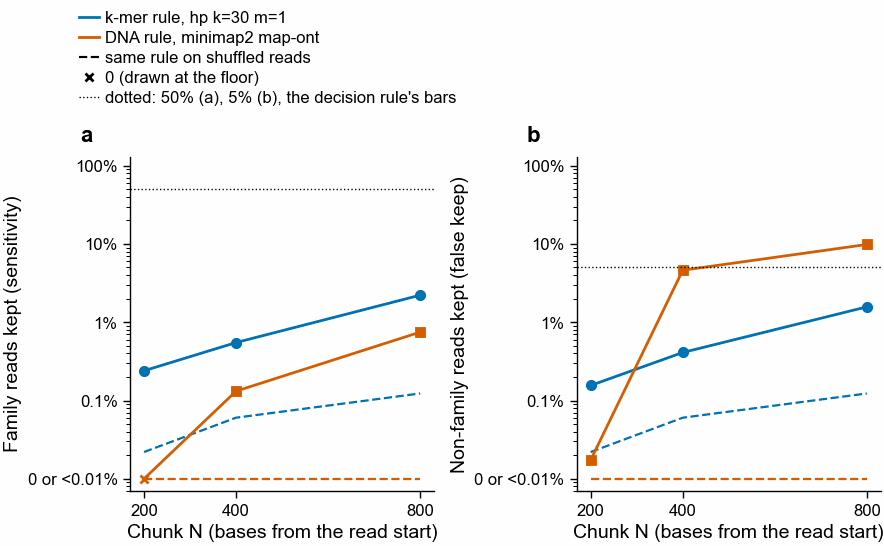

In [13]:
f2_k = tab.filter(
    (pl.col("setting") == best["setting"]) & (pl.col("holdout") == "ii")
).with_columns(label=pl.lit(f"k-mer rule, {best['setting']}"))
f2_d = comp_tab.filter(
    (pl.col("rule") == "DNA rule (minimap2)") & (pl.col("holdout") == "ii")
).with_columns(label=pl.lit("DNA rule, minimap2 map-ont"))
print(
    pl.concat(
        [
            f2_k.select(
                "label",
                "chunk_bases_requested",
                "sensitivity",
                "false_keep",
                "shuffled_keep",
            ),
            f2_d.select(
                "label",
                "chunk_bases_requested",
                "sensitivity",
                "false_keep",
                "shuffled_keep",
            ),
        ]
    )
)
fig = u.fig_by_chunk(f2_k, f2_d, "ii", f"{FIG}/f2_by_chunk_genus_holdout_{u.PFAM}")

**F2.** (a) Share of family reads kept and (b) share of non-family reads kept, against the
chunk length N, genus hold-out, Pfam truth. Dashed lines: the same rule on shuffled reads.
The y axis is spaced by ratio: the step from 0.1% to 1% takes as much room as the step from
10% to 100%. A rate of zero is drawn as an x on the bottom line.

## 9. Example read

The brief asks for one family read kept by the k-mer rule with the tarantulas held out (iii)
and not kept by the DNA rule. The read is picked by a rule written before looking: among
family reads kept by the best setting at hold-out (iii) and not by the DNA rule, the one
with the most chunk k-mers in the reference (ties: lowest read id). If none exists at the
best setting, the cell says so and shows the same printout at hold-out (ii) instead.

How to read it: the best setting is hp k = 30, a 2-letter code. The read's 30-letter
hydrophobic/polar pattern matches a cone snail protein, but at the residue level the same
stretch shares 8 of 59 residues with it. The hp match puts the read's residues 7-41 against
residues 31-65 of the cone snail protein Q9BPA0; DIAMOND aligns the same part of the read
to the C-terminal end (residues 62-77) of its tarantula best hit, P0DM66. This is the kind of chance pattern match the shuffled
copies measure (hp k = 30 keeps 0.06% of shuffled reads), not evidence that the rule found
the family.

In [14]:
u.print_hero(best, tr, n=400)

hold-out iii (tarantulas held out), hp k=30 m=1, N = 400: 63 family reads kept by the k-mer rule and not by the DNA rule

read SRR32537183.8117186/1, length 701 bases, truth: best Swiss-Prot hit P0DM66 (Selenotypus plumipes (Australian featherleg tarantula)), 44.6% identity, E = 1.66e-09

chunk (first 400 bases, as sequenced):
    1 CGGCATTTCCTCTCACTCACATTGGGTGTTTAACCGGTCCTTCTTCTTATACCGTGACAAGAAAGTTGTCGGTGTCTTTG
   81 TGACTTGCCTGCTCTATCTTCAGAGGAGAGTCCGCCGCCCGCAAGTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTT
  161 TTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTTCGAACAGAAAGAACTGATGTTTATTTATTATCTGCCGTTG
  241 GAAAACAGTACATCACATGAAATCGCCATGTTGTTACAACTTTTAACACGCTGTTTCGTCTTTTACATCGCATGTTACTT
  321 GCATTATACTTACACCATTCGTCTCTTTTGCTACAAATAAGGCACTTCACAGCATTCGTTTTTGCCAAGCGTGCATGACT

frame -1 translation (residue 1 starts at read base 400, reading toward base 1 on the reverse strand):
    1 SHARLAKTNAVKCLICSKRDEWCKYNASNMRCKRRNSVLKVVTTWRFHVMYCFPTADNK*
   61 TSVLSVRKKKKKKKKKKKKKKKKKKKKKKKKNLRAADSPLKIEQASHKDTDNFLVTV*E

>sp|P0DM66|TX31A_SELPU Orally active insecticidal peptide OS=Selenotypus plumipes OX=1395661 PE=1 SV=1
Length=79

 Score = 56.2 bits (134),  Expect = 1.66e-09
 Identities = 33/74 (44%), Positives = 47/74 (63%), Gaps = 0/74 (0%)
 Frame = -1

Query  542  LLVIAGIALLSVVCDSLELKECKNSPVKM\SRYFAASEPQQRACI/KIWESCTLGKNECC 369
            L +IAG+ALLSVVC + E+KE  +    + S +FAA EPQ+R C+   W SC    ++CC
Sbjct    4  LFIIAGLALLSVVCYTSEMKERSSFNEVL-SEFFAADEPQERDCL-GQWASCEPKNSKCC 61

Query  368  \KCLICSKRDEWCKYNA 320
                 C+ +  WC+Y A
Sbjct   62  -PNYACTWKYPWCRYRA 77




## 10. Decision

In [15]:
for name, rows in [("Pfam truth", f1_rows), ("UniProt subfamily truth", f1_sub)]:
    met, msg = u.decision_rule_met(rows)
    print(f"{name}, genus held out, N = 400: {msg} Continue: {'yes' if met else 'no'}")

Pfam truth, genus held out, N = 400: k-mer rule keeps 0.6% of family reads at false keep 0.4% (needs >= 50% at <= 5%: not met); DNA rule keeps 0.1% (needs < 10%: met). Continue: no
UniProt subfamily truth, genus held out, N = 400: k-mer rule keeps 0.4% of family reads at false keep 0.5% (needs >= 50% at <= 5%: not met); DNA rule keeps 0.1% (needs < 10%: met). Continue: no


## Summary and conclusions

**Claims the data supports**

1. The decision rule is not met. With the genus held out, the rule's best setting (hp
   k = 30, m = 1: the highest sensitivity among settings that keep 5% or fewer of
   non-family reads) keeps 117 of 21_270 family reads (0.55%) and 0.41% of non-family
   reads. Every setting that keeps 5% or fewer of non-family reads keeps under 4% of family
   reads, at every N.
2. In this sample, no rule separates Conotoxin-family (PF02950) reads from the other reads
   at the read start, the slow comparator included. DIAMOND blastx of the 400-base chunk
   keeps 62.8% of family reads and 56.7% of non-family reads with the genus held out. The
   test therefore cannot tell a good fast rule from a bad one with this family and these
   labels. That is the main result, more than any statement about k-mers.
3. The reason is shared precursor sequence. At protein k = 10 the reference k-mer found in
   the most read starts, IIAGLALLSV, is residues 6-15 of the signal peptide of P0DM66; it
   is in the first 400 bases of 5_403 family reads and 16_397 non-family reads. Summed over
   all 61 shared k-mers, those overlapping a signal peptide account for 35_537 non-family and
   5_483 family read matches; those only in the mature toxin, for 22 and 3. Pfam's
   PF02950 match on these tarantula proteins covers the signal peptide and propeptide too
   (B1P1F1 residues 3-74 of 79), so the family label itself rests partly on sequence that
   tarantula toxins of other families share.
4. The labels are unstable. The Pfam truth splits one UniProt subfamily: B1P1F1 carries
   PF02950, its paralog B1P1F2 does not. Relabelling by UniProt subfamily moves 48_508
   reads into the family (69_778 in all) and leaves the conclusion unchanged (F1 b).
5. There is a weak protein-level signal at the genus hold-out: protein k = 9 or 10, m = 1,
   keeps family reads at about 1.7 times its non-family rate (k = 10: 25.9% against
   14.9%). Protein k = 7, m = 2 keeps 39.1% against 25.0%. These rates are far above the
   shuffled rates (0.11% or less), so the matches are real sequence; they are not specific
   to the family.
6. With all tarantula proteins removed (cone snail and sea anemone proteins only), the DNA
   rule keeps no family read and DIAMOND on the chunk keeps 267 of 21_270 (1.3%) at a false
   keep of 2.1%. No k-mer setting, at any N, keeps family reads at more than twice its
   non-family rate, except settings that keep 3 family reads or fewer. Settings that keep
   many family reads keep more of the rest (dayhoff k = 10, m = 1, N = 400: 52.5% against
   64.5%).
7. The decision is fast: the median time per read is 0.15 to 0.21 ms in Python, more than
   3_000 times below the 800 ms chunk (SF3).

**Claims the data does not support**

- That a translated reduced-alphabet rule "reaches where DNA mapping does not". It keeps
  more family reads than DNA mapping only in settings that keep as many unrelated reads.
- That DNA mapping fails across genera. minimap2 keeps 0.13% of family reads but 4.6% of
  non-family reads at N = 400; that pattern points at the labels (paralogs on both sides),
  and was not looked into further.
- Anything about distance from the reference. Swiss-Prot has no *Selenobrachys* entry, so
  the genus hold-out removes nothing; its reference holds 8 proteins from three other
  tarantula genera.
- Anything about other families, tissues or newer chemistry. One run, one family, R9 flow
  cell, basecaller unknown. 93% of family reads (19_772 of 21_270) have the same best hit,
  so the reads test few distinct genes, and the 95% intervals over reads are too narrow.
- That the read start shows the same part of the transcript in every read. This is PCR
  cDNA. Forward-strand reads (9_467 of the 21_270 family reads) start at the 5' end, and the
  protein's N-terminus, signal peptide included, is in their first 400 bases in 98.7% of
  them. Reverse-strand reads (11_803) start with adapter, poly(T) and 3' UTR; their first
  400 bases overlap the coding alignment in 86.2% of them, but from the C-terminal end, and
  the protein's N-terminus is in the first 400 bases in only 0.16%. The signal-peptide
  matches therefore come from forward-strand reads, and a rule built on the mature toxin
  would be tested mostly on reverse-strand reads.
- That every family/non-family label is right. The truth step keeps one DIAMOND hit per
  read (`--max-target-seqs 1`), so between paralogs of equal length such as B1P1F1 (has
  PF02950) and B1P1F2 (no Pfam line, both 79 residues) DIAMOND's choice decides the label,
  and that choice is not visible in the output.
- That the pore-time numbers describe a real run. The model charges a read shorter than N
  the extra 500 bases when it is ejected, although such a read ends before any decision.

**Figures**: F1 `figures/292/f1_sensitivity_by_holdout_N400_PF02950.png`; F2
`figures/292/f2_by_chunk_genus_holdout_PF02950.png`; shared k-mers
`figures/292/fig_shared_kmers_protein_k10_N400_PF02950.png`; SF1 to SF4 and the family and
truth figures in `figures/292/`.

**Next smallest experiment**: before scoring any fast rule, find a target the slow
comparator can separate. For each candidate family in
[`292_data/toxin_family_candidates.csv`](292_data/toxin_family_candidates.csv), and for a
few non-toxin families with many reads, run DIAMOND blastx of the 400-base chunks against
that family's Swiss-Prot proteins (the step that already ran for PF02950) and keep only
families where it keeps at least half the family reads at a false keep of 5% or less, with
family membership checked against UniProt subfamilies as well as Pfam. Then rescore the
k-mer rule on those families only. Cost: about 10 minutes of DIAMOND per family on the
laptop; no new download. If no family passes, this sample cannot test the idea, and the
next step is a different sample, for example a tissue where the target family does not
share its signal peptide with most other transcripts.